In [ ]:
from google.colab import drive
import os
import zipfile

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
drive_path = "/content/drive/MyDrive"

for root, dirs, files in os.walk(drive_path):
    for file in files:
        if file.endswith(".zip"):
            print(os.path.join(root, file))

/content/drive/MyDrive/CAMO-V.1.0.zip


In [ ]:
zip_path = "/content/drive/MyDrive/CAMO-V.1.0.zip"

print("Is file:", os.path.isfile(zip_path))

Is file: True


In [ ]:
extract_path = "/content/CAMO"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file == "CAMO-V.1.0.zip":
            zip_path = os.path.join(root, file)
            print("CAMO ZIP found:", zip_path)

CAMO ZIP found: /content/drive/MyDrive/CAMO-V.1.0.zip


In [ ]:
import os
import zipfile

print("Is file:", os.path.isfile(zip_path))
print("Is valid ZIP:", zipfile.is_zipfile(zip_path))

Is file: True
Is valid ZIP: True


In [ ]:
extract_path = "/content/CAMO"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("CAMO dataset extracted successfully!")

CAMO dataset extracted successfully!


In [ ]:
import os

base_path = "/content/CAMO/CAMO-V.1.0-CVIU2019"

train_path = os.path.join(base_path, "Images/Train")
test_path = os.path.join(base_path, "Images/Test")
mask_path = os.path.join(base_path, "GT")


def check_pairs(image_path, mask_path):

    images = [
        f for f in os.listdir(image_path)
        if f.endswith(".jpg")
    ]

    missing_masks = []

    for image in images:

        mask_name = os.path.splitext(image)[0] + ".png"
        mask_file = os.path.join(mask_path, mask_name)

        if not os.path.exists(mask_file):
            missing_masks.append(mask_name)

    print("Total images:", len(images))
    print("Missing masks:", len(missing_masks))

    if len(missing_masks) == 0:
        print("All image-mask pairs are valid!")
    else:
        print("Missing files:", missing_masks[:10])


print("TRAINING DATA")
check_pairs(train_path, mask_path)

print("\nTESTING DATA")
check_pairs(test_path, mask_path)

TRAINING DATA
Total images: 1000
Missing masks: 0
All image-mask pairs are valid!

TESTING DATA
Total images: 250
Missing masks: 0
All image-mask pairs are valid!


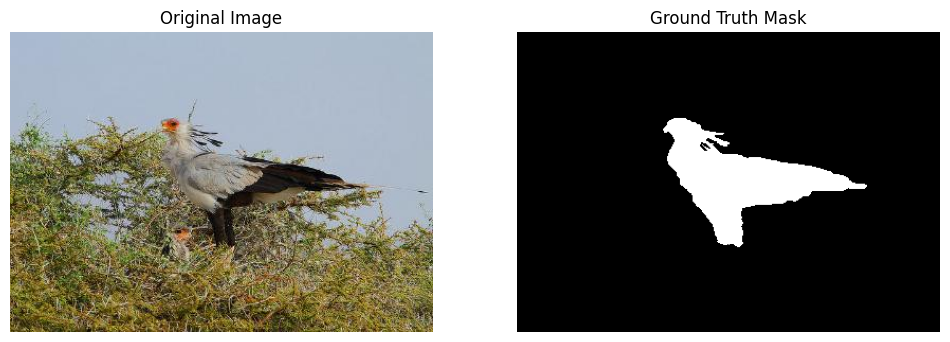

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import os

image_name = "camourflage_00377.jpg"

image = Image.open(
    os.path.join(train_path, image_name)
)

mask_name = image_name.replace(".jpg", ".png")

mask = Image.open(
    os.path.join(mask_path, mask_name)
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.show()

In [ ]:
from PIL import Image
import os

base_path = "/content/CAMO/CAMO-V.1.0-CVIU2019"

train_path = os.path.join(base_path, "Images/Train")
mask_path = os.path.join(base_path, "GT")

image_name = "camourflage_00377.jpg"

image = Image.open(
    os.path.join(train_path, image_name)
)

mask_name = image_name.replace(".jpg", ".png")

mask = Image.open(
    os.path.join(mask_path, mask_name)
)

print("Image loaded successfully!")
print("Mask loaded successfully!")

Image loaded successfully!
Mask loaded successfully!


In [ ]:
print("Image dimensions:", image.size)
print("Mask dimensions:", mask.size)

print("Image mode:", image.mode)
print("Mask mode:", mask.mode)

Image dimensions: (400, 284)
Mask dimensions: (400, 284)
Image mode: RGB
Mask mode: L


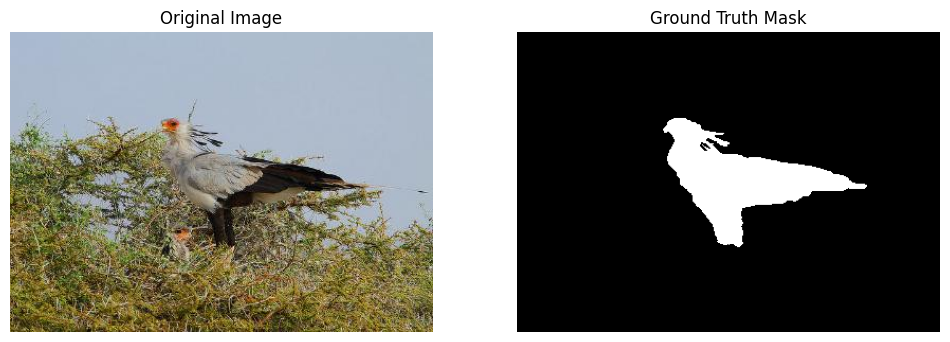

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.show()

In [ ]:
import numpy as np

image_array = np.array(image)
mask_array = np.array(mask)

print("Image shape:", image_array.shape)
print("Mask shape:", mask_array.shape)

print("Image pixel:", image_array[0, 0])
print("Mask pixel:", mask_array[0, 0])

Image shape: (284, 400, 3)
Mask shape: (284, 400)
Image pixel: [169 185 208]
Mask pixel: 0


In [ ]:
unique_values = np.unique(mask_array)

print("Unique mask values:", unique_values)
print("Number of unique values:", len(unique_values))

Unique mask values: [  0 255]
Number of unique values: 2


In [ ]:
normalized_mask = mask_array / 255.0
print("Original values:", np.unique(mask_array))
print("Normalized values:", np.unique(normalized_mask))

Original values: [  0 255]
Normalized values: [0. 1.]


In [ ]:
import torch
from torch.utils.data import Dataset
import os
from PIL import Image
import torchvision.transforms as transforms
import torch

In [ ]:
class CAMODataset(Dataset):

    def __init__(self, image_dir, mask_dir):

        self.image_dir = image_dir
        self.mask_dir = mask_dir

        self.images = sorted([
            file for file in os.listdir(image_dir)
            if file.endswith(".jpg")
        ])

        self.image_transform = transforms.Compose([
            transforms.Resize((256, 256)),
            transforms.ToTensor()
        ])

        self.mask_transform = transforms.Compose([
            transforms.Resize(
                (256, 256),
                interpolation=transforms.InterpolationMode.NEAREST
            ),
            transforms.ToTensor()
        ])

    def __len__(self):

        return len(self.images)

    def __getitem__(self, index):

        # Get image filename
        image_name = self.images[index]

        # Find corresponding mask filename
        mask_name = os.path.splitext(image_name)[0] + ".png"

        # Construct file paths
        image_path = os.path.join(self.image_dir, image_name)
        mask_path = os.path.join(self.mask_dir, mask_name)

        # Load image and mask
        image = Image.open(image_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")

        # Apply transformations
        image = self.image_transform(image)
        mask = self.mask_transform(mask)

        # Return image and mask
        return image, mask


In [ ]:
train_dataset = CAMODataset(
    image_dir=train_path,
    mask_dir=mask_path
)

print("Dataset length:", len(train_dataset))

Dataset length: 1000


In [ ]:
image, mask = train_dataset[0]

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)

print("Image dtype:", image.dtype)
print("Mask dtype:", mask.dtype)

print("Image min:", image.min().item())
print("Image max:", image.max().item())

print("Mask unique values:", torch.unique(mask))

Image shape: torch.Size([3, 256, 256])
Mask shape: torch.Size([1, 256, 256])
Image dtype: torch.float32
Mask dtype: torch.float32
Image min: 0.0
Image max: 1.0
Mask unique values: tensor([0., 1.])


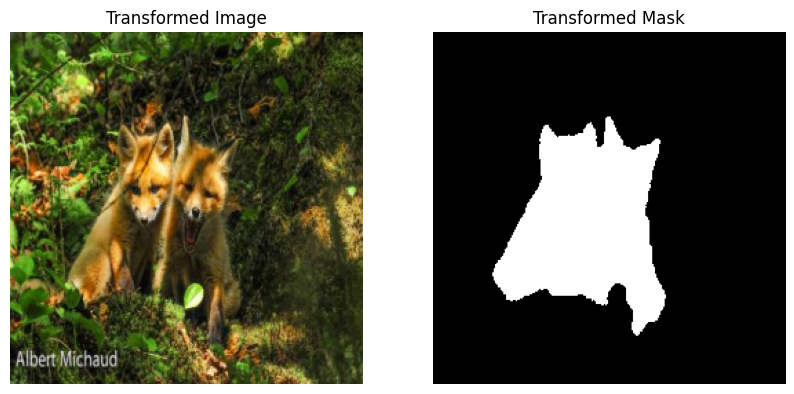

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image.permute(1, 2, 0))
plt.title("Transformed Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask.squeeze(0), cmap="gray")
plt.title("Transformed Mask")
plt.axis("off")

plt.show()

In [ ]:
from torch.utils.data import DataLoader

# Training dataset
train_dataset = CAMODataset(
    image_dir=train_path,
    mask_dir=mask_path
)

# Testing dataset
test_dataset = CAMODataset(
    image_dir=test_path,
    mask_dir=mask_path
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

Training samples: 1000
Testing samples: 250


In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False
)

In [ ]:
images, masks = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch mask shape:", masks.shape)

Batch image shape: torch.Size([4, 3, 256, 256])
Batch mask shape: torch.Size([4, 1, 256, 256])


In [ ]:
import torch
import timm

print("PyTorch version:", torch.__version__)
print("timm version:", timm.__version__)

pvt_models = timm.list_models(
    "*pvt_v2*",
    pretrained=True
)

print("\nAvailable pretrained PVTv2 models:")

for name in pvt_models:
    print(name)

In [ ]:
import timm
import torch

backbone = timm.create_model(
    "pvt_v2_b0.in1k",
    pretrained=True,
    features_only=True
)

print(backbone)

In [ ]:
import torch
import torch.nn as nn
class ChannelAttention(nn.Module):

    def __init__(self, channels, reduction=16):
        super().__init__()

        self.avg_pool = nn.AdaptiveAvgPool2d(1)

        self.fc = nn.Sequential(

            # First convolution
            nn.Conv2d(
                channels,
                channels // reduction,
                kernel_size=1
            ),

            nn.ReLU(inplace=True),

            # Second convolution
            nn.Conv2d(
                channels // reduction,
                channels,
                kernel_size=1
            ),

            nn.Sigmoid()
        )

    def forward(self, x):

        attention = self.avg_pool(x)

        attention = self.fc(attention)

        return x * attention

In [ ]:
class SpatialAttention(nn.Module):

    def __init__(self, kernel_size=7):
        super().__init__()

        self.conv = nn.Conv2d(
            2,
            1,
            kernel_size=kernel_size,
            padding=kernel_size // 2,
            bias=False
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        # Average across channels
        avg_out = torch.mean(x, dim=1, keepdim=True)

        # Maximum across channels
        max_out, _ = torch.max(x, dim=1, keepdim=True)

        # Combine both maps
        combined = torch.cat([avg_out, max_out], dim=1)

        # Generate spatial attention weights
        attention = self.sigmoid(self.conv(combined))

        # Apply attention
        return x * attention

In [ ]:
class CombinedAttention(nn.Module):

    def __init__(self, channels):
        super().__init__()

        self.channel_attention = ChannelAttention(channels)
        self.spatial_attention = SpatialAttention()

    def forward(self, x):

        x = self.channel_attention(x)

        x = self.spatial_attention(x)

        return x

In [ ]:
class FeatureProjection(nn.Module):

    def __init__(self, in_channels, out_channels=64):
        super().__init__()

        self.projection = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1
            ),

            nn.BatchNorm2d(out_channels),

            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.projection(x)

In [ ]:
import torch.nn.functional as F

class DecoderBlock(nn.Module):

    def __init__(self, channels=64):
        super().__init__()

        self.conv = nn.Sequential(

            nn.Conv2d(
                channels * 2,
                channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                channels,
                channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True)
        )

        self.attention = CombinedAttention(channels)

    def forward(self, deep_features, skip_features):

        # Resize deep features to match skip features
        deep_features = F.interpolate(
            deep_features,
            size=skip_features.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        # Combine both feature maps
        x = torch.cat(
            [deep_features, skip_features],
            dim=1
        )

        # Convolution
        x = self.conv(x)

        # Apply attention
        x = self.attention(x)

        return x

In [ ]:
# Create projection layers
project1 = FeatureProjection(32, 64)
project2 = FeatureProjection(64, 64)
project3 = FeatureProjection(160, 64)
project4 = FeatureProjection(256, 64)

# Create dummy PVT features
features = [
    torch.randn(1, 32, 64, 64),
    torch.randn(1, 64, 32, 32),
    torch.randn(1, 160, 16, 16),
    torch.randn(1, 256, 8, 8)
]

# Apply projections
projected_features = [
    project1(features[0]),
    project2(features[1]),
    project3(features[2]),
    project4(features[3])
]

for i, feature in enumerate(projected_features):
    print(f"Projected Stage {i+1}:", feature.shape)

In [ ]:
class PVTAttentionUNet(nn.Module):

  """
    ARCHITECTURE DECISION LOG

    Decision 1: Use PVTv2-B0 from timm as the backbone.
    Reason: A pretrained transformer backbone provides
    multi-scale image features instead of learning all
    visual features from scratch.

    Decision 2: Use pretrained ImageNet weights.
    Reason: Transfer learning provides useful initial
    feature representations.

    Decision 3: Freeze the backbone during training.
    Reason: Reduce trainable parameters and training cost.

    Decision 4: Project backbone features to 64 channels.
    Reason: Make feature dimensions consistent for
    decoder operations.

    Decision 5: Use channel and spatial attention.
    Reason: Help the decoder emphasize important feature
    channels and spatial regions.

    Decision 6: Use skip connections in the decoder.
    Reason: Combine deeper semantic features with
    higher-resolution spatial information.

    Decision 7: Use a 1x1 convolution for the output.
    Reason: Convert decoder features into a
    single-channel segmentation prediction.

    Decision 8: Upsample output to the input resolution.
    Reason: Ensure the predicted mask has the same
    spatial dimensions as the input image.
    """

    def __init__(self, pretrained=True):
        super().__init__()

        # PVT backbone
        self.backbone = timm.create_model(
            "pvt_v2_b0.in1k",
            pretrained=pretrained,
            features_only=True
        )

        # Feature projections
        self.project1 = FeatureProjection(32, 64)
        self.project2 = FeatureProjection(64, 64)
        self.project3 = FeatureProjection(160, 64)
        self.project4 = FeatureProjection(256, 64)

        # Decoder blocks
        self.decoder1 = DecoderBlock(64)
        self.decoder2 = DecoderBlock(64)
        self.decoder3 = DecoderBlock(64)

        # Final output layer
        self.output_layer = nn.Conv2d(
            64,
            1,
            kernel_size=1
        )

    def forward(self, x):

        input_size = x.shape[-2:]

        # Extract PVT features
        features = self.backbone(x)

        # Project features
        f1 = self.project1(features[0])
        f2 = self.project2(features[1])
        f3 = self.project3(features[2])
        f4 = self.project4(features[3])

        # Decode
        d1 = self.decoder1(f4, f3)
        d2 = self.decoder2(d1, f2)
        d3 = self.decoder3(d2, f1)

        # Generate segmentation logits
        output = self.output_layer(d3)

        # Resize to original input dimensions
        output = F.interpolate(
            output,
            size=input_size,
            mode="bilinear",
            align_corners=False
        )

        return output


In [ ]:
model = PVTAttentionUNet(pretrained=True)

dummy_image = torch.randn(1, 3, 256, 256)

model.eval()

with torch.no_grad():
    output = model(dummy_image)

print("Input shape:", dummy_image.shape)
print("Output shape:", output.shape)

In [ ]:
# Freeze PVT backbone
for param in model.backbone.parameters():
    param.requires_grad = False

# Count parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print("Frozen parameters:", total_params - trainable_params)

In [ ]:
model = PVTAttentionUNet(pretrained=True)

print("PVT Attention U-Net created successfully!")

In [ ]:
for param in model.backbone.parameters():
    param.requires_grad = False

In [ ]:
total_params = sum(p.numel() for p in model.parameters())

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print("Frozen parameters:", total_params - trainable_params)

In [ ]:
dummy_image = torch.randn(1, 3, 256, 256)

model.eval()

with torch.no_grad():
    output = model(dummy_image)

print("Input shape:", dummy_image.shape)
print("Output shape:", output.shape)

In [ ]:
images, masks = next(iter(train_loader))

print("Image shape:", images.shape)
print("Mask shape:", masks.shape)
print("Image minimum:", images.min().item())
print("Image maximum:", images.max().item())

In [ ]:
class CAMOPVTDataset(torch.utils.data.Dataset):

    def __init__(self, image_dir, mask_dir):

        self.image_dir = image_dir
        self.mask_dir = mask_dir

        self.images = sorted(os.listdir(image_dir))

        self.image_transform = transforms.Compose([
            transforms.Resize((256, 256)),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )
        ])

        self.mask_transform = transforms.Compose([
            transforms.Resize(
                (256, 256),
                interpolation=transforms.InterpolationMode.NEAREST
            ),
            transforms.ToTensor()
        ])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):

        image_name = self.images[index]

        image_path = os.path.join(
            self.image_dir, image_name
        )

        mask_path = os.path.join(
            self.mask_dir,
            os.path.splitext(image_name)[0] + ".png"
        )

        image = Image.open(image_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")

        image = self.image_transform(image)
        mask = self.mask_transform(mask)

        mask = (mask > 0.5).float()

        return image, mask


In [ ]:
pvt_train_dataset = CAMOPVTDataset(
    train_path,
    mask_path
)

pvt_test_dataset = CAMOPVTDataset(
    test_path,
    mask_path
)

pvt_train_loader = DataLoader(
    pvt_train_dataset,
    batch_size=4,
    shuffle=True
)

pvt_test_loader = DataLoader(
    pvt_test_dataset,
    batch_size=4,
    shuffle=False
)

In [ ]:
images, masks = next(iter(pvt_train_loader))

print("Image shape:", images.shape)
print("Mask shape:", masks.shape)

print("Image minimum:", images.min().item())
print("Image maximum:", images.max().item())

print("Mask unique values:", torch.unique(masks))

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Running on CPU.")


In [ ]:
import time
import torch
import torch.nn as nn

device = torch.device("cpu")
model = model.to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001
)

# Keep the frozen backbone in evaluation mode
model.train()
model.backbone.eval()

batch_times = []

for i, (images, masks) in enumerate(pvt_train_loader):

    images = images.to(device)
    masks = masks.to(device)

    start = time.perf_counter()

    optimizer.zero_grad(set_to_none=True)

    outputs = model(images)

    loss = criterion(outputs, masks)

    loss.backward()

    optimizer.step()

    elapsed = time.perf_counter() - start

    if i >= 3:
        batch_times.append(elapsed)

    if i == 12:
        break

average_time = sum(batch_times) / len(batch_times)

estimated_epoch_time = average_time * len(pvt_train_loader)

print("Average batch time:", round(average_time, 2), "seconds")
print("Batches per epoch:", len(pvt_train_loader))
print("Estimated epoch time:", round(estimated_epoch_time / 60, 2), "minutes")
print("Estimated 5 epochs:", round(estimated_epoch_time * 5 / 3600, 2), "hours")

In [ ]:
num_epochs = 5

for epoch in range(num_epochs):

    model.train()

    # Keep frozen PVT backbone in evaluation mode
    model.backbone.eval()

    total_loss = 0

    for images, masks in pvt_train_loader:

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)

        loss = criterion(outputs, masks)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    epoch_loss = total_loss / len(pvt_train_loader)

    print(
        f"Epoch [{epoch+1}/{num_epochs}], "
        f"Loss: {epoch_loss:.4f}"
    )


In [ ]:
torch.save(
    model.state_dict(),
    "pvt_attention_unet.pth"
)

print("PVT Attention U-Net model saved successfully!")

In [ ]:
model.eval()

print("Model is now in evaluation mode.")

print("Test images:", len(pvt_test_dataset))

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Get one batch from test loader
images, masks = next(iter(pvt_test_loader))

# Select one image and its ground truth
image = images[0:1].to(device)
ground_truth = masks[0]

# Generate prediction
model.eval()

with torch.no_grad():
    output = model(image)
    prediction = torch.sigmoid(output)

# Convert prediction to binary mask
predicted_mask = (prediction > 0.5).float()

# Reverse ImageNet normalization
img = images[0].permute(1, 2, 0).numpy()

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

img = img * std + mean
img = np.clip(img, 0, 1)

# Display results
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(ground_truth.squeeze().numpy(), cmap="gray")
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(predicted_mask[0].cpu().squeeze().numpy(), cmap="gray")
plt.title("PVT Prediction")
plt.axis("off")

plt.show()

In [ ]:
model.eval()

total_error = 0
total_pixels = 0

with torch.no_grad():
    for images, masks in pvt_test_loader:

        images = images.to(device)
        masks = masks.to(device)

        # Generate predictions
        outputs = model(images)
        predictions = torch.sigmoid(outputs)

        # Calculate absolute pixel differences
        error = torch.abs(predictions - masks)

        total_error += error.sum().item()
        total_pixels += masks.numel()

# Calculate overall MAE
mae = total_error / total_pixels

print(f"Test MAE: {mae:.4f}")


In [ ]:
!pip install pysodmetrics

In [ ]:
from py_sod_metrics import Smeasure, Emeasure

print("S-measure and E-measure imported successfully!")

In [ ]:
import numpy as np
import torch
from py_sod_metrics import Smeasure, Emeasure

# Initialize evaluation metrics
sm = Smeasure()
em = Emeasure()

model.eval()

with torch.no_grad():

    for images, masks in pvt_test_loader:

        images = images.to(device)

        # Generate predictions
        outputs = model(images)
        predictions = torch.sigmoid(outputs)

        # Move predictions and masks to CPU
        predictions = predictions.cpu().numpy()
        masks = masks.cpu().numpy()

        # Calculate metrics for each image
        for i in range(len(images)):

            pred = predictions[i, 0]
            gt = masks[i, 0]

            # Convert to uint8 format (0-255)
            pred = (pred * 255).astype(np.uint8)
            gt = (gt * 255).astype(np.uint8)

            # Update metrics
            sm.step(pred, gt)
            em.step(pred, gt)

# Get final results
s_results = sm.get_results()
e_results = em.get_results()

print("S-measure:", s_results["sm"])
print("E-measure:", e_results["em"])

In [ ]:
print("E-measure result type:", type(e_results))
print("Available keys:", e_results.keys())
print("Full result:", e_results)

In [ ]:
e_results["em"]["curve"]

In [ ]:
e_curve = e_results["em"]["curve"]

print(f"Adaptive E-measure: {e_results['em']['adp']:.4f}")
print(f"Mean E-measure: {np.mean(e_curve):.4f}")
print(f"Maximum E-measure: {np.max(e_curve):.4f}")